1. Imports

In [1]:
from pathlib import Path
import copy
import random
from typing import cast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

2. Setup

In [2]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

PROJECT_ROOT = Path.cwd().parent
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(parents=True, exist_ok = True)

PyTorch: 2.13.0
Device: mps


3. Load Data

In [3]:
train_df = pd.read_csv(SPLITS_DIR / "train.csv")
val_df = pd.read_csv(SPLITS_DIR / "validation.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")

FEATURE_COLUMNS = ["brand", "price", "stock", "rating"]
TARGET_COLUMN = "category"

x_train_df = train_df[FEATURE_COLUMNS].copy()
y_train_text = train_df[TARGET_COLUMN].astype(str)

x_val_df = val_df[FEATURE_COLUMNS].copy()
y_val_text = val_df[TARGET_COLUMN].astype(str)

x_test_df = test_df[FEATURE_COLUMNS].copy()
y_test_text = test_df[TARGET_COLUMN].astype(str)

print("Train:", x_train_df.shape)
print("Val:", x_val_df.shape)
print("Test:", x_test_df.shape)

Train: (156, 4)
Val: (20, 4)
Test: (20, 4)


4. Encode Features

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["price", "stock", "rating"]),
    ("categorical", categorical_pipeline, ["brand"])])

x_train = preprocessor.fit_transform(x_train_df)
x_val = preprocessor.transform(x_val_df)
x_test = preprocessor.transform(x_test_df)

if hasattr(x_train, "toarray"):
    x_train = x_train.toarray()
    x_val = x_val.toarray()
    x_test = x_test.toarray()

x_train = np.asarray(x_train, dtype=np.float32)
x_val = np.asarray(x_val, dtype=np.float32)
x_test = np.asarray(x_test, dtype=np.float32)

print("x_train:", x_train.shape)
print("x_val:", x_val.shape)
print("x_test:", x_test.shape)

x_train: (156, 24)
x_val: (20, 24)
x_test: (20, 24)


5. Encode Target labels

In [5]:
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)

known_classes = set(label_encoder.classes_)

unknown_val= sorted(set(y_val_text) - known_classes)
unknown_test = sorted(set(y_test_text) - known_classes)

if unknown_val or unknown_test:
    raise ValueError(
        f"Validation-only labels: {unknown_val}; test-only labels: {unknown_test}")

y_val = label_encoder.transform(y_val_text)
y_test = label_encoder.transform(y_test_text)

classes = label_encoder.classes_.tolist()
num_classes = len(classes)

print("Classes:", classes)
print("Number of classes:", num_classes)

Classes: ['CPU', 'Case', 'GPU', 'Headset', 'Laptop', 'Monitor', 'Motherboard', 'Mouse', 'PSU', 'RAM', 'SSD']
Number of classes: 11


6. Convert Numpy arrays into tensors

In [6]:
x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
x_val_tensor = torch.tensor(x_val, dtype=torch.float32)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

print("Train features:", x_train_tensor.shape)
print("Train labels:", y_train_tensor.shape)

print("Validation features:", x_val_tensor.shape)
print("Validation labels:", y_val_tensor.shape)

print("Test features:", x_test_tensor.shape)
print("Test labels:", y_test_tensor.shape)

Train features: torch.Size([156, 24])
Train labels: torch.Size([156])
Validation features: torch.Size([20, 24])
Validation labels: torch.Size([20])
Test features: torch.Size([20, 24])
Test labels: torch.Size([20])


7. Dataset & DataLoader

In [7]:
BATCH_SIZE = 32

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 5
Validation batches: 1
Test batches: 1


8. Build Neural Network

In [8]:
class ProductCategoryNN(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        return self.network(x)

input_dim = x_train_tensor.shape[1]

model = ProductCategoryNN(input_dim=input_dim, num_classes=num_classes).to(device)
print(model)
print(model.parameters())

ProductCategoryNN(
  (network): Sequential(
    (0): Linear(in_features=24, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=11, bias=True)
  )
)
<generator object Module.parameters at 0x119119460>


9. Loss and Optimizer

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 100
PATIENCE = 15

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


10. Training Loop

In [10]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_predictions = []
    all_targets = []

    for features, labels in loader:
        features = features.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(features)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * features.size(0)
        predictions = torch.argmax(logits, dim=1)
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_targets.extend(labels.detach().cpu().tolist())

        average_loss = total_loss / len(loader.dataset)
        accuracy = accuracy_score(all_targets, all_predictions)

        return average_loss, accuracy

In [11]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []}


best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_accuracy = run_epoch(model, val_loader, criterion)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_accuracy)
    history["val_acc"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} |"
            f"Train loss: {train_loss:.4f} |"
            f"Train accuracy: {train_accuracy:.4f} |"
            f"Validation loss: {val_loss:.4f} |"
            f"Validation accuracy: {val_accuracy:.4f}"
        )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping ad epoch:", epoch)
        break

model.load_state_dict(best_state)
print("Best validation loss:", best_val_loss)

Epoch 001 |Train loss: 0.4910 |Train accuracy: 0.0938 |Validation loss: 2.3931 |Validation accuracy: 0.1000
Epoch 010 |Train loss: 0.4901 |Train accuracy: 0.1875 |Validation loss: 2.3704 |Validation accuracy: 0.2000
Epoch 020 |Train loss: 0.4816 |Train accuracy: 0.1250 |Validation loss: 2.3466 |Validation accuracy: 0.1500
Epoch 030 |Train loss: 0.4786 |Train accuracy: 0.1562 |Validation loss: 2.3164 |Validation accuracy: 0.2000
Epoch 040 |Train loss: 0.4540 |Train accuracy: 0.4062 |Validation loss: 2.2716 |Validation accuracy: 0.2000
Epoch 050 |Train loss: 0.4449 |Train accuracy: 0.4062 |Validation loss: 2.2109 |Validation accuracy: 0.3500
Epoch 060 |Train loss: 0.4113 |Train accuracy: 0.5625 |Validation loss: 2.1380 |Validation accuracy: 0.4000
Epoch 070 |Train loss: 0.3705 |Train accuracy: 0.5000 |Validation loss: 2.0563 |Validation accuracy: 0.4500
Epoch 080 |Train loss: 0.3340 |Train accuracy: 0.5938 |Validation loss: 1.9721 |Validation accuracy: 0.4500
Epoch 090 |Train loss: 0.376

11. Plot Training History

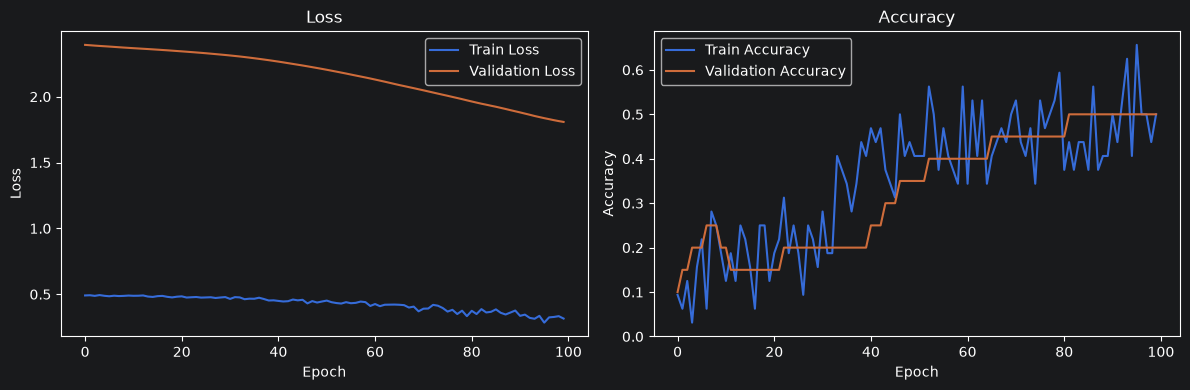

In [12]:
fig, axes = plt.subplots(1,2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["train_acc"], label="Train Accuracy")
axes[1].plot(history["val_acc"], label="Validation Accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

12. Test Evaluation

In [13]:
test_loss, test_accuracy = run_epoch(model, test_loader, criterion)
model.eval()

with torch.no_grad():
    logits = model(x_test_tensor.to(device))
    test_predictions = (torch.argmax(logits, dim=1).cpu().numpy())

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))

print(classification_report(y_test, test_predictions, labels=np.arange(num_classes),target_names=classes, zero_division=0))


Test Loss: 1.5592
Test Accuracy: 0.6
              precision    recall  f1-score   support

         CPU       0.50      0.75      0.60         4
        Case       0.00      0.00      0.00         2
         GPU       0.57      0.80      0.67         5
     Headset       0.00      0.00      0.00         0
      Laptop       0.00      0.00      0.00         0
     Monitor       0.00      0.00      0.00         2
 Motherboard       0.00      0.00      0.00         1
       Mouse       0.00      0.00      0.00         1
         PSU       0.00      0.00      0.00         0
         RAM       0.75      1.00      0.86         3
         SSD       0.67      1.00      0.80         2

    accuracy                           0.60        20
   macro avg       0.23      0.32      0.27        20
weighted avg       0.42      0.60      0.50        20



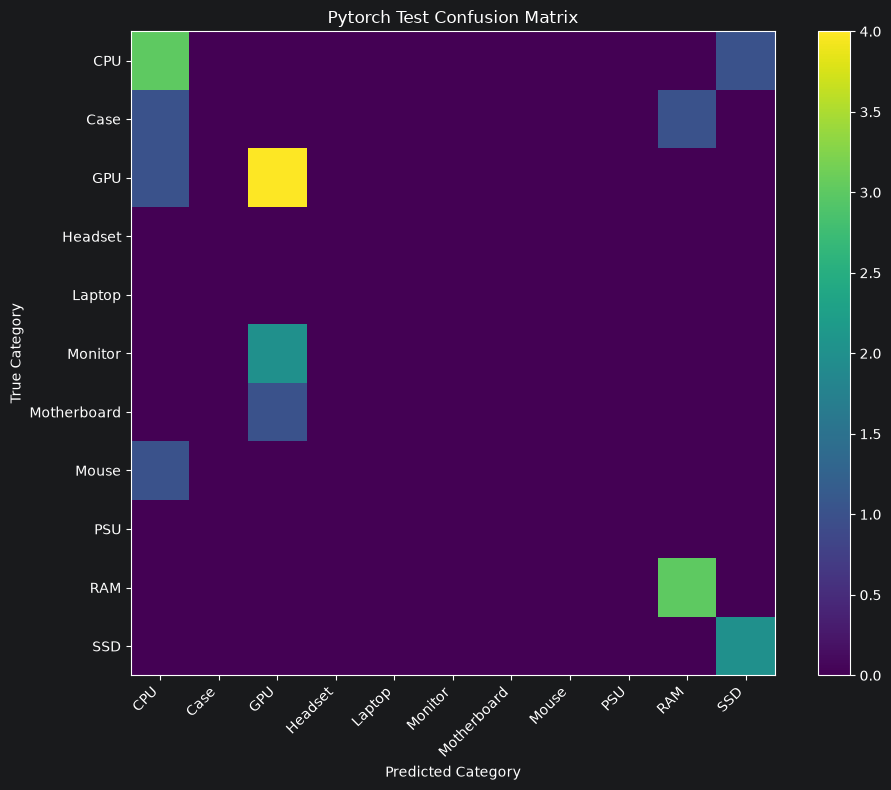

In [14]:
cm = confusion_matrix(y_test, test_predictions, labels=np.arange(num_classes))

fig, ax = plt.subplots(figsize=(10,8))
image = ax.imshow(cm, interpolation="nearest")

ax.set_title("Pytorch Test Confusion Matrix")
ax.set_xlabel("Predicted Category")
ax.set_ylabel("True Category")

ax.set_xticks(np.arange(num_classes))
ax.set_yticks(np.arange(num_classes))

ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticklabels(classes)

fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

13. Save Model

In [15]:
MODEL_PATH = MODELS_DIR / "pytorch_product_category.pt"
PREPROCESSOR_PATH = MODELS_DIR / "pytorch_preprocessor.joblib"
LABEL_ENCODER_PATH = MODELS_DIR / "pytorch_label_encoder.joblib"

checkpoint = {
    "model_state_dict" : model.cpu().state_dict(),
    "input_dim" : input_dim,
    "num_classes" : num_classes,
    "classes" : classes,
    "feature_columns" : FEATURE_COLUMNS,
    "target_columns" : TARGET_COLUMN
}

torch.save(checkpoint, LABEL_ENCODER_PATH)

joblib.dump(preprocessor, PREPROCESSOR_PATH)
joblib.dump(label_encoder, LABEL_ENCODER_PATH)

model = model.to(device)

print("Saved:", MODEL_PATH)
print("Saved:", PREPROCESSOR_PATH)
print("Saved:", LABEL_ENCODER_PATH)


Saved: /Users/macbookpro/PycharmProjects/Techcart_ai/models/pytorch_product_category.pt
Saved: /Users/macbookpro/PycharmProjects/Techcart_ai/models/pytorch_preprocessor.joblib
Saved: /Users/macbookpro/PycharmProjects/Techcart_ai/models/pytorch_label_encoder.joblib


14. Load saved model & predict

In [16]:
loaded_preprocessor = joblib.load(
    MODELS_DIR / "pytorch_preprocessor.joblib"
)

loaded_label_encoder = joblib.load(
    MODELS_DIR / "pytorch_label_encoder.joblib"
)

sample_product = pd.DataFrame([{
    "brand": (
        x_train_df["brand"].dropna().iloc[0]
        if x_train_df["brand"].notna().any()
        else "Unknown"
    ),
    "price": x_train_df["price"].median(),
    "stock": x_train_df["stock"].median(),
    "rating": x_train_df["rating"].median()
}])

sample_array = loaded_preprocessor.transform(sample_product)

if hasattr(sample_array, "toarray"):
    sample_array = sample_array.toarray()

sample_array = np.asarray(sample_array, dtype=np.float32)

sample_tensor = torch.tensor(
    sample_array,
    dtype=torch.float32
).to(device)

model.eval()

with torch.no_grad():
    logits = model(sample_tensor)
    predicted_index = torch.argmax(logits, dim=1).item()

predicted_category = loaded_label_encoder.inverse_transform(
    [predicted_index]
)[0]

display(sample_product)
print("Predicted category:", predicted_category)

,brand,price,stock,rating
0,Corsair,176.65,16.0,4.7


Predicted category: SSD


In [17]:
model.eval()

with torch.no_grad():
    logits = model(sample_tensor)

    probabilities = torch.softmax(logits, dim=1)[0].cpu().numpy()
    probability_df = pd.DataFrame({
        "Category": loaded_label_encoder.classes_,
        "Probability": probabilities
    })

    probability_df = probability_df.sort_values(
        "Probability", ascending=False).reset_index(drop=True)

display(probability_df)

,Category,Probability
0,SSD,0.185115
1,RAM,0.143953
2,CPU,0.136348
3,Case,0.098610
4,Mouse,0.087339
5,PSU,0.078859
6,GPU,0.066314
7,Monitor,0.059978
8,Motherboard,0.054825
9,Laptop,0.052246
